In [5]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), 'utils'))

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from task import generate_trials, load_params

In [6]:
task_list  = ['pure', 'harmonic', 'wn']
params     = load_params()
dt         = params['timing']['dt']

trials = {}
for task_type in task_list:
    trials[task_type] = generate_trials(
        task_type, task_list, mode='test', batch_size=6,
        rng=np.random.default_rng(0))

for tt, tr in trials.items():
    print(f'{tt:10s}  n_freq={tr.n_freq}  n_in={tr.n_in} (freq+fixation+context)  '
          f'tdim={tr.tdim}  stim_on={tr.stim_on}  labels={tr.labels}')

pure        n_freq=50  n_in=54 (freq+fixation+context)  tdim=240  stim_on=50  labels=['Go (PT Go low/PT Go high)', 'Go (PT Go low/PT Go high)', 'PT No-Go', 'Go (PT Go low/PT Go high)', 'Go (PT Go low/PT Go high)', 'PT No-Go']
harmonic    n_freq=50  n_in=54 (freq+fixation+context)  tdim=240  stim_on=50  labels=['Go (HCT Go low/HCT Go high)', 'Go (HCT Go low/HCT Go high)', 'HCT No-Go', 'Go (HCT Go low/HCT Go high)', 'Go (HCT Go low/HCT Go high)', 'HCT No-Go']
wn          n_freq=50  n_in=54 (freq+fixation+context)  tdim=240  stim_on=50  labels=['Go (WN Go)', 'WN No-Go', 'Go (WN Go)', 'WN No-Go', 'Go (WN Go)', 'WN No-Go']


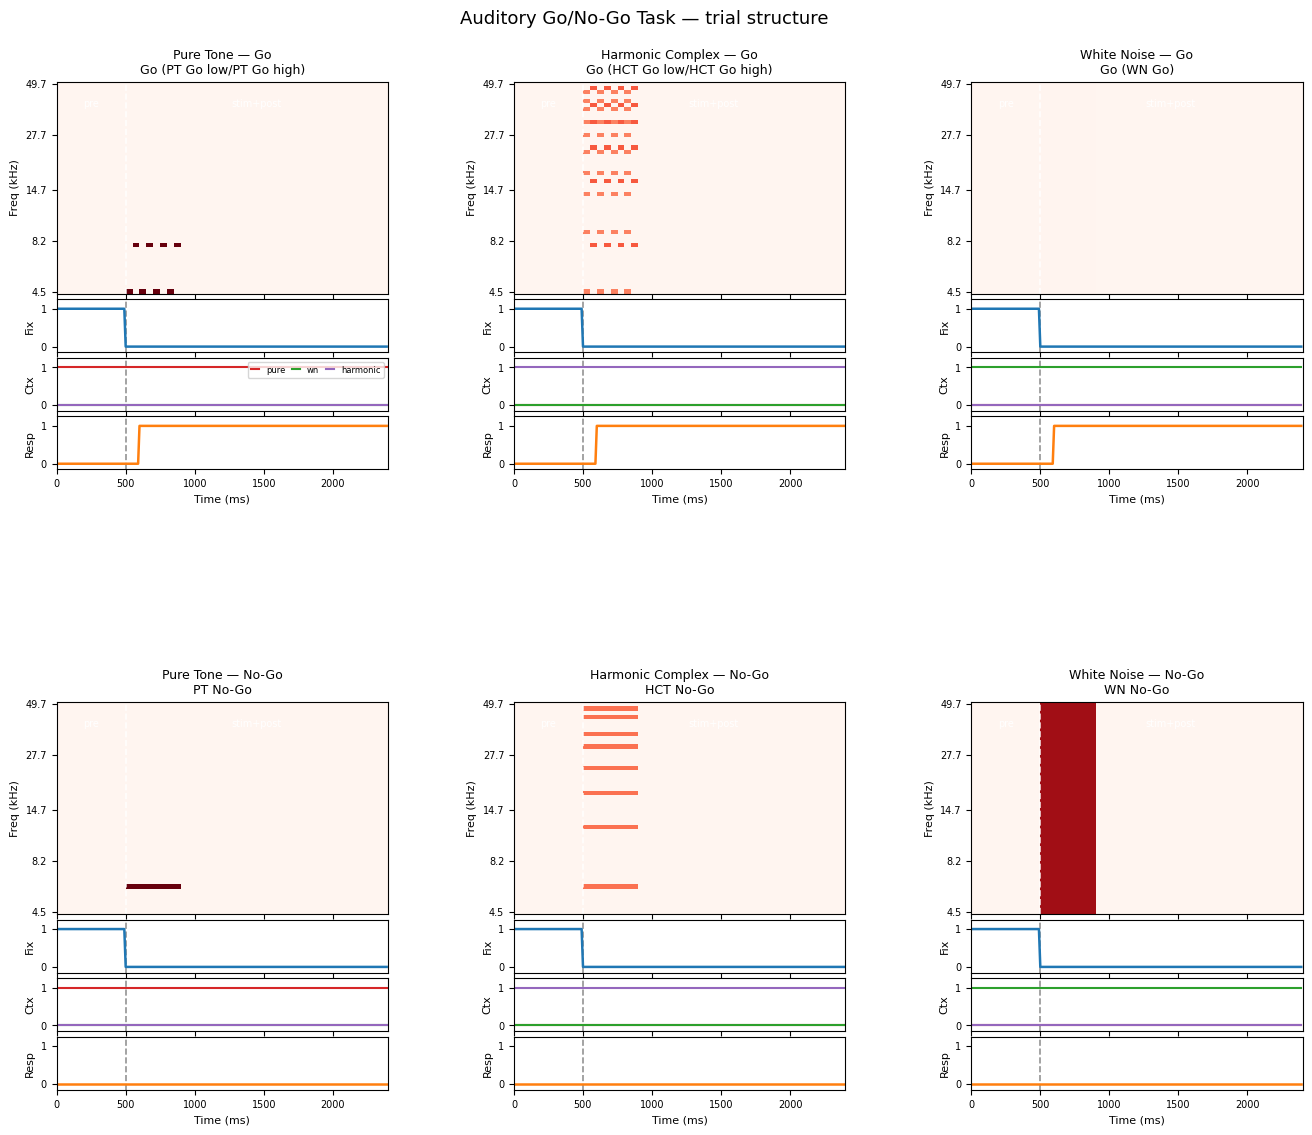

In [7]:
TASK_NAMES = {'pure': 'Pure Tone', 'harmonic': 'Harmonic Complex', 'wn': 'White Noise'}
CTX_LABELS  = ['pure', 'wn', 'harmonic']
CTX_COLORS  = ['tab:red', 'tab:green', 'tab:purple']

# shared colormap scale across frequency channels only (exclude fixation/context)
vmax_global = max(
    trials[tt].x[:, :, :trials[tt].n_freq].max()
    for tt in task_list
)

fig = plt.figure(figsize=(14, 12))
outer = gridspec.GridSpec(
    2, 3, figure=fig,
    hspace=0.6, wspace=0.38,
    left=0.08, right=0.97, top=0.91, bottom=0.07)

for col, task_type in enumerate(task_list):
    trial   = trials[task_type]
    t_ms    = np.arange(trial.tdim) * dt
    t_edges = np.append(t_ms, t_ms[-1] + dt)
    grid_hz = trial.grid_hz
    n_freq  = trial.n_freq

    go_idx   = int(np.where(trial.is_go)[0][0])
    nogo_idx = int(np.where(~trial.is_go)[0][0])

    for row, (idx, role) in enumerate([(go_idx, 'Go'), (nogo_idx, 'No-Go')]):
        inner = gridspec.GridSpecFromSubplotSpec(
            4, 1, subplot_spec=outer[row, col],
            height_ratios=[4, 1, 1, 1], hspace=0.06)

        ax_in   = fig.add_subplot(inner[0])
        ax_fix  = fig.add_subplot(inner[1], sharex=ax_in)
        ax_ctx  = fig.add_subplot(inner[2], sharex=ax_in)
        ax_resp = fig.add_subplot(inner[3], sharex=ax_in)

        # ── input heatmap (freq channels only) ───────────────────────
        stim_mat = trial.x[:, idx, :n_freq].T
        ax_in.pcolormesh(
            t_edges, np.arange(n_freq + 1), stim_mat,
            cmap='Reds', vmin=0, vmax=vmax_global, shading='flat')

        stim_on_ms = trial.stim_on * dt
        for ax in (ax_in, ax_fix, ax_ctx, ax_resp):
            ax.axvline(stim_on_ms,
                       color='white' if ax is ax_in else 'gray',
                       lw=1.2, ls='--', alpha=0.85)

        tick_idxs = np.round(np.linspace(0, n_freq - 1, min(5, n_freq))).astype(int)
        ax_in.set_yticks(tick_idxs + 0.5)
        ax_in.set_yticklabels(
            ['{:.1f}'.format(grid_hz[i] / 1000) for i in tick_idxs], fontsize=7)
        ax_in.set_ylabel('Freq (kHz)', fontsize=8)
        ax_in.set_ylim(0, n_freq)

        mid_pre  = stim_on_ms / 2
        mid_stim = (stim_on_ms + t_ms[-1]) / 2
        ax_in.text(mid_pre,  n_freq * 0.92, 'pre',       color='white',
                   ha='center', va='top', fontsize=7)
        ax_in.text(mid_stim, n_freq * 0.92, 'stim+post', color='white',
                   ha='center', va='top', fontsize=7)

        ax_in.set_title(
            f'{TASK_NAMES[task_type]} — {role}\n{trial.labels[idx]}',
            fontsize=9)

        # ── fixation channel ─────────────────────────────────────────
        ax_fix.plot(t_ms, trial.x[:, idx, n_freq], color='tab:blue', lw=1.8)
        ax_fix.set_ylim(-0.15, 1.25)
        ax_fix.set_yticks([0, 1])
        ax_fix.set_yticklabels(['0', '1'], fontsize=7)
        ax_fix.set_ylabel('Fix', fontsize=8)

        # ── context channels ─────────────────────────────────────────
        ctx_data = trial.x[:, idx, n_freq + 1 : n_freq + 1 + 3]  # (tdim, 3)
        for ci, (lbl, col_c) in enumerate(zip(CTX_LABELS, CTX_COLORS)):
            ax_ctx.plot(t_ms, ctx_data[:, ci], color=col_c, lw=1.5, label=lbl)
        ax_ctx.set_ylim(-0.15, 1.25)
        ax_ctx.set_yticks([0, 1])
        ax_ctx.set_yticklabels(['0', '1'], fontsize=7)
        ax_ctx.set_ylabel('Ctx', fontsize=8)
        if col == 0 and row == 0:
            ax_ctx.legend(fontsize=6, loc='upper right', ncol=3,
                          handlelength=1, columnspacing=0.8)

        # ── target response ──────────────────────────────────────────
        ax_resp.plot(t_ms, trial.y[:, idx, 0], color='tab:orange', lw=1.8)
        ax_resp.set_ylim(-0.15, 1.25)
        ax_resp.set_yticks([0, 1])
        ax_resp.set_yticklabels(['0', '1'], fontsize=7)
        ax_resp.set_ylabel('Resp', fontsize=8)
        ax_resp.set_xlabel('Time (ms)', fontsize=8)
        ax_resp.tick_params(axis='x', labelsize=7)

        plt.setp(ax_in.get_xticklabels(),  visible=False)
        plt.setp(ax_fix.get_xticklabels(), visible=False)
        plt.setp(ax_ctx.get_xticklabels(), visible=False)

fig.suptitle('Auditory Go/No-Go Task — trial structure', fontsize=13, y=0.97)
plt.savefig('task_structure.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
vmax_global

np.float32(1.0)